# What can 50 bottles tell us about a 500 mL label?

Companion tutorial for Blog Post 8. **Every bottle is simulated.** The hypothetical process has independent normal fills, mean 498 mL and standard deviation 10 mL. All sample sizes, repetition counts and random streams were specified before inspecting results.

The three experiments are different: bootstrap the original sample; draw fresh samples to check t-interval coverage; draw fresh samples under the 500 mL null to interpret a two-sided test.

## Setup and assumptions

Run with the packages in `requirements.txt`. The generator knows the population SD, but the interval and test estimate it from each sample. The exact t calibration relies on independent normal fills and a stable mean. This is not evidence about a brand or legal compliance.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display
from contextlib import redirect_stdout
from io import StringIO

ROOT = Path.cwd()
if not (ROOT / 'config.json').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'code'))
from analyze import run as simulate
from verify import run as independently_verify
from make_figures import bootstrap_figure, coverage_figure, null_figure
get_ipython().run_line_magic('matplotlib', 'inline')
pd.set_option('display.precision', 4)
config = json.loads((ROOT / 'config.json').read_text())
settings = {'Random seed':config['root_seed'], 'True mean (mL)':config['population_mean_ml'],
            'True SD (mL)':config['population_sd_ml'], 'Null mean (mL)':config['null_mean_ml'],
            'Bottles per sample':config['sample_size'], 'Bootstrap repetitions':config['bootstrap_repetitions'],
            'Coverage samples':config['coverage_repetitions'], 'Null samples':config['null_repetitions'],
            'Significance level':config['alpha']}
display(pd.Series(settings, name='Pre-specified setting').to_frame())

,Pre-specified setting
Random seed,2.0261e+07
True mean (mL),4.9800e+02
True SD (mL),1.0000e+01
Null mean (mL),5.0000e+02
Bottles per sample,5.0000e+01
Bootstrap repetitions,5.0000e+03
Coverage samples,5.0000e+03
Null samples,5.0000e+03
Significance level,5.0000e-02


## 1. Generate the original sample and independent experiments

`analyze.py` uses four child streams of the fixed seed: one for the original sample, one for bootstrap indices, one for coverage, and one for the null model. Saved raw arrays let the independent checker inspect every calculation without regenerating or sharing a helper.

In [2]:
with redirect_stdout(StringIO()):
    summary = simulate()
arrays = np.load(ROOT / 'data/simulation_inputs.npz')
sample = arrays['sample']
n = config['sample_size']
sample_mean = sample.mean()
sample_sd = sample.std(ddof=1)
standard_error = sample_sd / np.sqrt(n)
display(pd.DataFrame({'quantity':['sample size','sample mean (mL)','sample SD (mL)','SE of mean (mL)'],
                      'value':[n, sample_mean, sample_sd, standard_error]}))

,quantity,value
0,sample size,50.0000
1,sample mean (mL),495.5368
2,sample SD (mL),9.9211
3,SE of mean (mL),1.4031


## 2. Bootstrap the same 50 observations

Each row of the saved index matrix contains 50 independent draws **with replacement** from indices 0 through 49. Repetition of an index is allowed. The bootstrap means are centered near the original sample mean, which need not equal the true population mean.

resamples            5000.0000
bootstrap SE (mL)       1.3586
Name: Bootstrap, dtype: float64

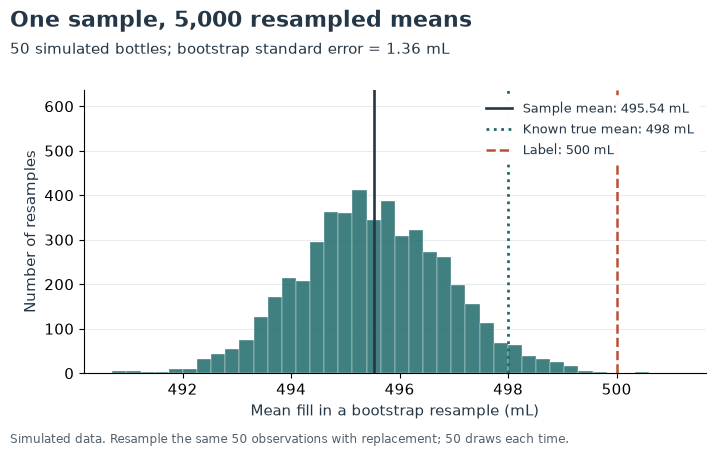

In [3]:
indices = arrays['bootstrap_indices']
bootstrap_means = sample[indices].mean(axis=1)
display(pd.Series({'resamples':len(bootstrap_means),
                   'bootstrap SE (mL)':bootstrap_means.std(ddof=1)}, name='Bootstrap'))
fig = bootstrap_figure(summary)
display(fig)
plt.close(fig)

## 3. Draw fresh samples and measure interval coverage

These are **Student t intervals**, not bootstrap percentile intervals. Each fresh sample has its own mean and estimated standard deviation. An interval covers the true mean when its lower bound is no larger than 498 and its upper bound is no smaller than 498. The picture shows the first 100 samples in generation order; the reported coverage uses all 5,000.

intervals                             5000.000
covered                               4733.000
coverage (%)                            94.660
Monte Carlo SE (percentage points)       0.318
Name: Coverage, dtype: float64

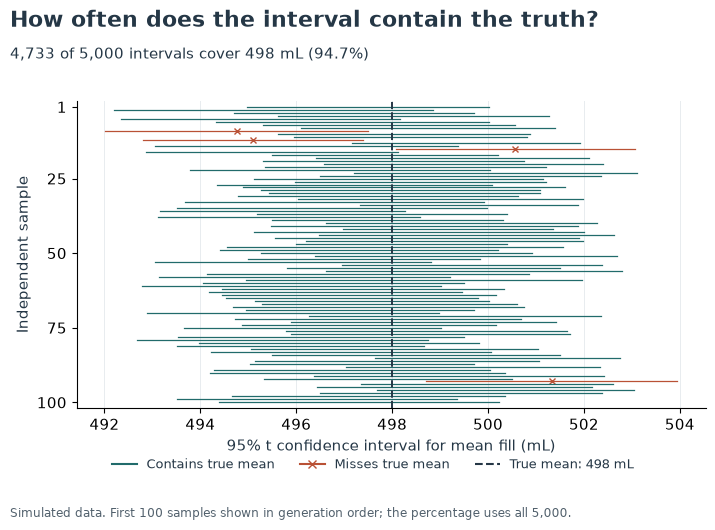

In [4]:
fresh_samples = arrays['coverage_samples']
critical_t = stats.t.ppf(1 - config['alpha']/2, n-1)
centers = fresh_samples.mean(axis=1)
half_widths = critical_t * fresh_samples.std(axis=1, ddof=1) / np.sqrt(n)
lower, upper = centers-half_widths, centers+half_widths
covered = (lower <= config['population_mean_ml']) & (config['population_mean_ml'] <= upper)
coverage_mc_se = np.sqrt(covered.mean()*(1-covered.mean())/len(covered))
display(pd.Series({'intervals':len(covered), 'covered':covered.sum(),
                   'coverage (%)':100*covered.mean(),
                   'Monte Carlo SE (percentage points)':100*coverage_mc_se}, name='Coverage'))
fig = coverage_figure(summary)
display(fig)
plt.close(fig)

## 4. Simulate the world in which the 500 mL null is true

For the null experiment the population mean is **500 mL**, while sample size and variation remain the same. A statistic is as extreme as the observed one when its **absolute** value is at least as large. The add-one Monte Carlo p-value is `(extreme_count + 1)/(simulation_count + 1)`. The analytic two-sided t p-value is retained as a reference, not used to replace the simulation.

The upper panel shades the fixed 5% rejection regions. The lower panel shades the sample-specific p-value tails; these are different concepts.

observed t                 -3.1810
extreme simulations        15.0000
simulation p                0.0032
analytic t p                0.0025
critical absolute t         2.0096
null rejection rate (%)     5.1800
Name: Test, dtype: float64

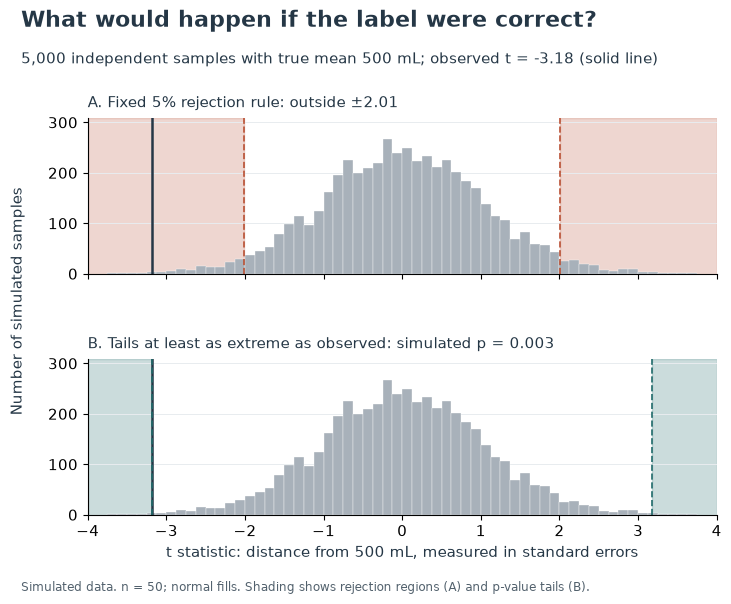

In [5]:
null_samples = arrays['null_samples']
null_t = (null_samples.mean(axis=1)-config['null_mean_ml']) / (null_samples.std(axis=1, ddof=1)/np.sqrt(n))
observed_t = (sample_mean-config['null_mean_ml']) / standard_error
extreme_count = np.count_nonzero(np.abs(null_t) >= abs(observed_t))
simulation_p = (extreme_count+1)/(len(null_t)+1)
analytic = stats.ttest_1samp(sample, popmean=config['null_mean_ml'], alternative='two-sided')
display(pd.Series({'observed t':observed_t, 'extreme simulations':extreme_count,
                   'simulation p':simulation_p, 'analytic t p':analytic.pvalue,
                   'critical absolute t':critical_t,
                   'null rejection rate (%)':100*np.mean(np.abs(null_t)>critical_t)}, name='Test'))
fig = null_figure(summary)
display(fig)
plt.close(fig)

## 5. Independent checks

The verifier recomputes all 5,000 bootstrap means, 5,000 interval endpoints and 5,000 null statistics from retained raw inputs using Python's `statistics` library. It also reconciles the original interval and test with SciPy's independent one-sample t interface and checks calibration against the model's exact t distribution.

In [6]:
with redirect_stdout(StringIO()):
    checks = independently_verify()
display(pd.DataFrame({'Check':['Bootstrap means','Coverage intervals','Null statistics','Original t test and CI'],
                      'Records':[checks['bootstrap_rows_recomputed'],checks['coverage_intervals_recomputed'],
                                 checks['null_statistics_recomputed'],1],
                      'Status':['Passed']*4}))

,Check,Records,Status
0,Bootstrap means,5000,Passed
1,Coverage intervals,5000,Passed
2,Null statistics,5000,Passed
3,Original t test and CI,1,Passed


## Interpretation and limits

The particular sample provides evidence against a 500 mL population mean under the stated model, but its average is also below the known 498 mL. Sampling noise affects the estimated size of a shortfall. A 95% confidence procedure concerns repeated-sample coverage; it is not a guarantee about 95% of individual bottles. A p-value is a null-model tail probability, not the probability that the label is correct.

For real data, serial dependence, batches, measurement error and changes in the process would need attention. Finite Monte Carlo simulations introduce additional approximation error.

## Sources

- [NIST: Confidence limits for the mean and the one-sample t test](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)
- [SciPy: bootstrap](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bootstrap.html)
- [SciPy: ttest_1samp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_1samp.html)

All numbers in this notebook come from the simulation specified in `config.json`; these references support the methods, not an empirical claim about bottle fills.